Ryan Hughes Assignment 2 CNET 5051, Fall 2026
---

**Overall Instructions:** Due by Friday, Oct. 30th, 11:00pm EST. Please submit a .pdf of your answers
via Canvas, including a url to your .ipynb notebook in a public GitHub repository. Use the provided LATEX
template for your submission. Please name your Canvas submission as Lastname.pdf, (e.g. Trujillo.pdf). If
you need help with LATEX or GitHub, please visit during office hours or post questions to the Canvas. Include
your code in a (well-documented, commented, clear) assignment02.ipynb file. Scores for the code-based
questions below will be based on your written responses and code.

**Problem 1 (20 points)**
In this question we will work with degree-controlled random graph null models.

(a) The Configuration Model (5 points).
First, implement the configuration model in Python. Your function should take a list of integers
as a degree sequence, and return a graph where each vertex has the assigned degree. You graph
may contain duplicate edges and self-loops.

(b) The Chung Lu Model (5 points).
Next, implement the Chung Lu random graph model. Remember that this model creates an
edge between nodes i and j with independent probabilities defined by vertex degree and the total
number of edges in the graph:
pij = kikj
2m ,
where 2m := ∑︁
i ki.
Your implementation should take a list of integers as a degree sequence, and return a simple graph
with approximately the desired degree sequence.

(c) Model Differences (5 points).
For the degree sequence degrees=[8,5,5,4,3,2,2,2,1,1,1,1,1,1,1], generate a thousand ran-
dom graphs using the Configuration Model and the Chung Lu model, then:

(i) Plot the average adjacency matrix for each model. This should be a heatmap of:
⟨A⟩ = 1
N
N∑︂
i=1
Ai
where N is the number of generated random graphs, and Ai is the adjacency matrix of the
ith graph. (Hint: matplotlib’s imshow is useful for displaying matrix data.)

(ii) Choose two graph metrics: one that should be approximately the same across graphs gen-
erated by both models, and one that should diverge significantly between the two models.
For each metric, make a plot (histogram, kernel-density estimate, or cumulative distribution
function) showing the distribution of the metric across all generated graphs from each model.
Note: For this stage you may remove self-loops and duplicate edges from your configuration
model graphs if it helps make a direct comparison to Chung Lu graphs.

(d) Discussion (5 points).
Discuss the above results briefly. Why do the models produce similar results under some metrics
and different results under others?


[(0, 5), (1, 3), (2, 3), (3, 4), (4, 1), (5, 2), (6, 2), (7, 4), (8, 2), (9, 0), (10, 0), (11, 0), (12, 0), (13, 0), (14, 0)]
Depicting the configuration nodel graphically to show any self-loops that can occur: 


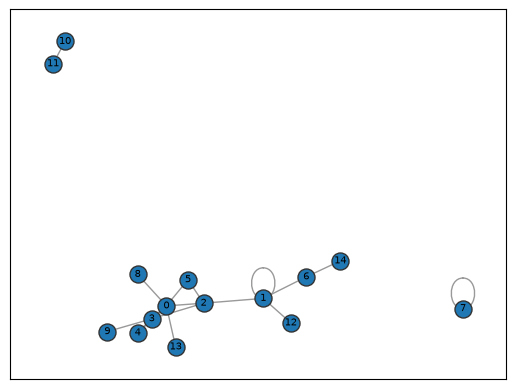

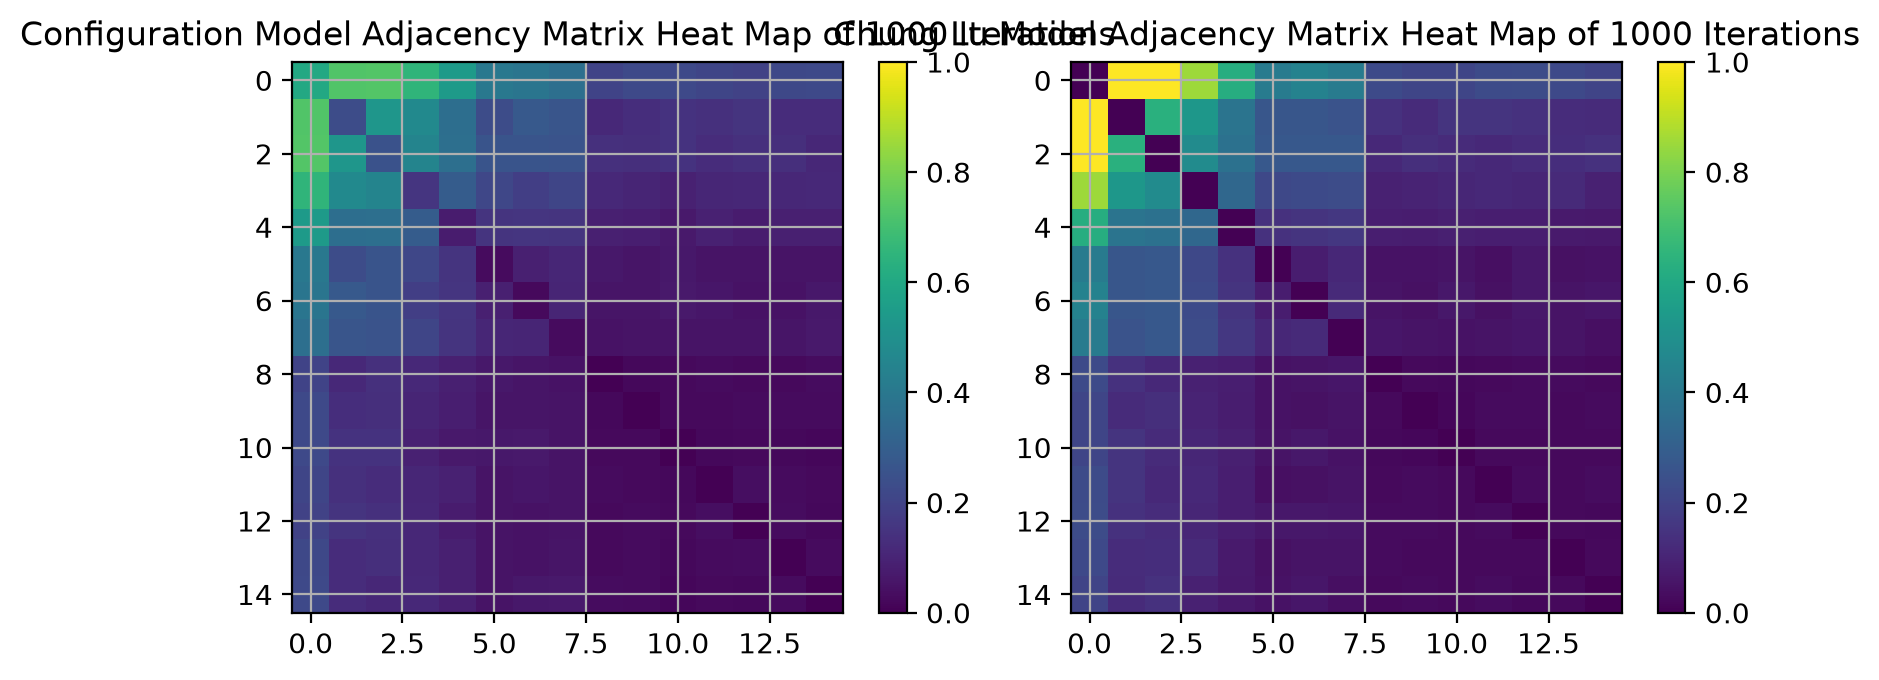

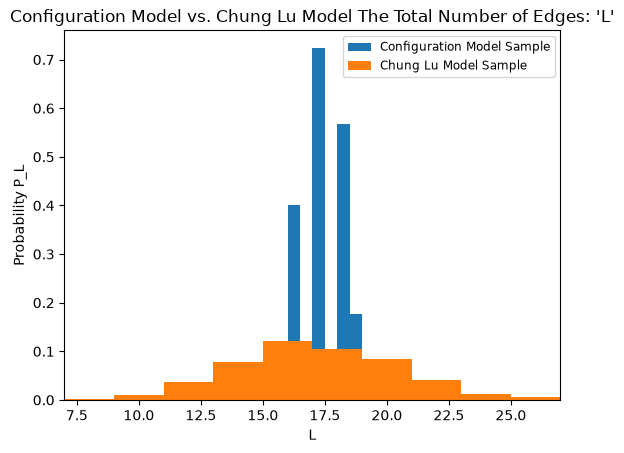

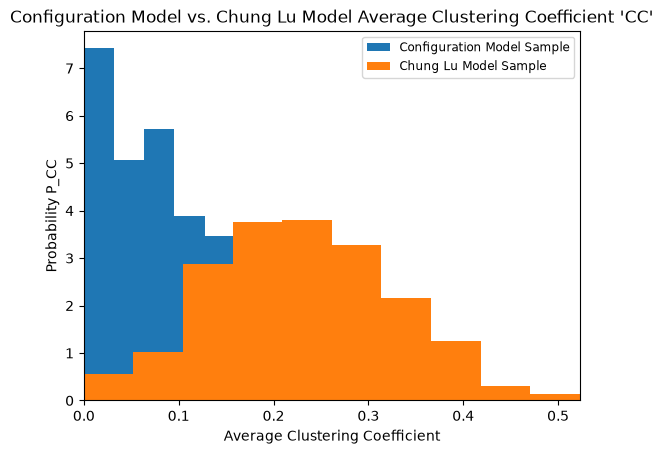

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from itertools import combinations
import logging
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.special import comb

def configuration_model_from_degree_sequence(degree_sequence, return_simple=True):
    """
    Generate a random graph using the configuration model from a given degree sequence
    without using the NetworkX built-in function.

    The configuration model generates a random graph that preserves the degree 
    sequence of nodes by assigning "stubs" or "half-edges" to each node and 
    randomly pairing these stubs to form edges. This process can result in 
    graphs with self-loops and parallel edges, which can be removed if needed.

    Parameters
    ----------
    degree_sequence : list of int
        A list representing the degree of each node in the graph. The sum of 
        the degrees in this sequence must be even for the configuration model 
        to create a valid graph.

    Returns
    -------
    G : networkx.MultiGraph
        A multigraph generated from the given degree sequence. The graph may 
        contain self-loops and parallel edges, which are allowed in the 
        configuration model.

    Notes
    -----
    - This method works by assigning "stubs" or "half-edges" to nodes based on 
      their degree and then randomly pairing them to form edges. The resulting 
      graph can have self-loops and parallel edges.
    - Self-loops and parallel edges can be removed post-generation if a simple 
      graph is required using NetworkX's `nx.Graph(G)`.
    - The degree sequence must have an even sum for a valid graph construction. 
      If the sum of the degrees is odd, no graph can be constructed.

    Time Complexity
    ---------------
    The time complexity is O(E), where E is the number of edges in the graph.

    Example
    -------
    >>> degree_sequence = [3, 3, 2, 2, 1, 1]
    >>> G = configuration_model_from_degree_sequence(degree_sequence)
    >>> nx.is_graphical(degree_sequence)
    True
    """

    # Check if the degree sequence is valid (sum of degrees must be even)
    if sum(degree_sequence) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")

    # Create stubs list: node i appears degree_sequence[i] times
    stubs = []
    for node, degree in enumerate(degree_sequence):
        stubs.extend([node] * degree)

    # Shuffle stubs to randomize the pairing process
    np.random.shuffle(stubs)

    # Initialize an empty multigraph
    G = nx.MultiGraph()

    # Add nodes to the graph
    G.add_nodes_from(range(len(degree_sequence)))

    # Pair stubs to create edges
    while stubs:
        u = stubs.pop()
        v = stubs.pop()

        # Add the edge to the graph
        G.add_edge(u, v)

    if return_simple:
        # Convert the multigraph to a simple graph (remove parallel edges)
        G_simple = nx.Graph(G)  # This removes parallel edges by default

        return G_simple

    else:
        return G


def chung_lu_model_from_degree_sequence(degree_sequence, return_simple=True):
    """
    Generate a random graph using the Chung Lu model from a given degree sequence
    without using the NetworkX built-in function.

    The Chung Lu model generates a random graph that preserves the degree 
    sequence of nodes by...

    Parameters
    ----------
    degree_sequence : list of int
        A list representing the degree of each node in the graph. The sum of 
        the degrees in this sequence must be even for the Chung Lu model 
        to create a valid graph.

    Returns
    -------
    G : networkx.Graph
        A multigraph generated from the given degree sequence. The graph may 
        contain self-loops and parallel edges, which are allowed in the 
        configuration model.

    Notes
    -----
    - This method works by assigning "stubs" or "half-edges" to nodes based on 
      their degree and then randomly pairing them to form edges. The resulting 
      graph can have self-loops and parallel edges.
    - Self-loops and parallel edges can be removed post-generation if a simple 
      graph is required using NetworkX's `nx.Graph(G)`.
    - The degree sequence must have an even sum for a valid graph construction. 
      If the sum of the degrees is odd, no graph can be constructed.

    Time Complexity
    ---------------
    The time complexity is O(M+N), where M is the number of edges in the graph and N the number of nodes

    Example
    -------
    >>> degree_sequence = [3, 3, 2, 2, 1, 1]
    >>> G = configuration_model_from_degree_sequence(degree_sequence)
    >>> nx.is_graphical(degree_sequence)
    True
    """
    #Instatiate G:
    G = nx.Graph()
    N=len(degree_sequence) #Total number of nodes by taking the length of the degree sequence
    G.add_nodes_from(range(N))

    # Check if the degree sequence is valid (sum of degrees must be even)
    if sum(degree_sequence) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")

    #First calculate the total number of edges in the graph by taking the sum of the degree sequence
    total_edges = sum(degree_sequence)
    
    #Ensure degree sequence is sorted:
    degree_sequence=np.sort(degree_sequence,descending=True)

    for i in range(0,N-1):#for all nodes
        j=i+1#Look at the next possible node to connect to...
        #and, get the probability of connecting to this node:
        pij = min((degree_sequence[i] * degree_sequence[j]) / (total_edges),1)
        
        #while there are additional valid other nodes available to connect to...
        while j < N and pij > 0: 
            if (pij < 1):#(i.e., while the probability is not 100% or 0%)
                r = np.random.rand()#draw a random chance
                #and calculate the following to grab one of these additional other nodes:
                j += int(np.floor(np.log(r)/np.log(1-pij)))

            if j < N:#while there are additional other nodes to process...
                #get the additional other node's probability of connecting to:
                q = min((degree_sequence[i] * degree_sequence[j]) / (total_edges),1)
                r = np.random.rand()#draw a random chance
                if r < q/pij:#if the random chance is less than the probability of connecting to this new other node relative to the simple next in the sequence:
                    G.add_edge(i,j)#add an edge to the new other node
                pij=q#update the probability of connection with the last processed node
                j+=1#move forward relative to the new other node
    return G

#(b) Testing
degrees=[8,5,5,4,3,2,2,2,1,1,1,1,1,1,1]
chung_lu_graph = chung_lu_model_from_degree_sequence(degrees)
print(chung_lu_graph.degree)
#(c) Testing
chung_lus = 0
configs = 0
num_edges_list_config=[]
num_edges_list_chunglu=[]
cc_list_config=[]
cc_list_chunglu=[]
pos = []
for i in range(1,1001):
    cc_list_config.append(nx.average_clustering((configuration_model_from_degree_sequence(degrees))))
    cc_list_chunglu.append(nx.average_clustering((chung_lu_model_from_degree_sequence(degrees))))
    num_edges_list_config.append((configuration_model_from_degree_sequence(degrees)).number_of_edges())
    num_edges_list_chunglu.append((chung_lu_model_from_degree_sequence(degrees)).number_of_edges())
    configs += (nx.adjacency_matrix(configuration_model_from_degree_sequence(degrees)))
    chung_lus += (nx.adjacency_matrix(chung_lu_model_from_degree_sequence(degrees)))
    model=configuration_model_from_degree_sequence(degrees)
    pos = nx.spring_layout(model)

configs = configs/1000
chung_lus = chung_lus/1000

print("Depicting the configuration nodel graphically to show any self-loops that can occur: ")
fig2 = plt.plot()
nx.draw_networkx(model, pos, node_size=150, edgecolors='.2', with_labels=True, font_size='x-small', edge_color='.6')


fig, ax = plt.subplots(1,2,figsize=(8,3.5),dpi=200)

im1 = ax[0].imshow(configs.todense(),cmap='viridis',vmin = 0, vmax = 1)
ax[0].set_title("Configuration Model Adjacency Matrix Heat Map of 1000 Iterations")
ax[0].grid(True)
ax[0].autoscale(False)

im2 = ax[1].imshow(chung_lus.todense(),cmap='viridis',vmin = 0, vmax = 1)
ax[1].set_title("Chung Lu Model Adjacency Matrix Heat Map of 1000 Iterations")
ax[1].grid(True)
ax[1].autoscale(False)


fig.tight_layout()
fig.colorbar(im1)
fig.colorbar(im2)
plt.show()

# (c) (ii)
#For the metrics, are there any specific ones we want here?
# Could I do just degree distribution? and total of edges?

N=len(degrees)

#---Plotting the Total Number of Edges 'L'
#Starting the plotting process
fig, ax = plt.subplots()#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
ax.hist(num_edges_list_config,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
ax.hist(num_edges_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Configuration Model vs. Chung Lu Model The Total Number of Edges: 'L'")
ax.set_xlabel("L")
ax.set_ylabel("Probability P_L")
true_min=min(min(num_edges_list_config), min(num_edges_list_chunglu))
true_max=max(max(num_edges_list_config), max(num_edges_list_chunglu))
ax.set_xlim(true_min,true_max)
plt.show()

#---Plotting the Average Clustering Coefficient 'CC'
#Starting the plotting process
fig, ax = plt.subplots()#Note: fig is the plot container, while ax (i.e., the 'axes') is the plot itself
ax.hist(cc_list_config,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
ax.hist(cc_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Configuration Model vs. Chung Lu Model Average Clustering Coefficient 'CC'")
ax.set_xlabel("Average Clustering Coefficient")
ax.set_ylabel("Probability P_CC")
true_min=min(min(cc_list_config), min(cc_list_chunglu))
true_max=max(max(cc_list_config), max(cc_list_chunglu))
ax.set_xlim(true_min,true_max)
plt.show()

Discussing the Results:
My heat map comparing the two models shows the general adjacency matrix value for each pair of nodes. Notably we see the Chung Lu model guaranteed no self-loops, while the Configuration Model had some. The general trend of the higher degree nodes (i.e., in this case node 0,1,2,etc., as I enforced and provided a sorted list from highest degree to lowest as input) remained the region with the highest overall adjacency matrix average values amongst the 1000 iterations. This indicates they had a high probability to be connected amongst one another, and in turn were thus often connected to one another. This is expected as the high degree nodes are the most likely for any random node to be connected to. In the case of Chung Lu however some of these pairs appeared to be connected close to if not 100% of the time, in contrast to the Configuration where these high-degree to high-degree pairs (e.g., node 0 to node 1), were the highest but did not occur 100% of the time across iterations.

As for my two metrics I chose for part c, I did the total number of edges 'L', and the average clustering coefficient. Here we can see the total number of edges, is approximately the same across graphs generated by both models, with both models coalescing around the same average total number of edges, of roughly ~17 or so, albeit at different probability levels. The average clustering coefficient on the other hand is much closer to 0 in the case of the configuration model while the Chung Lu model is relatively higher than 0. This is most likely due to the presence of self-loops and multi-edges that can occur in the configuration model. This artifact of the self-loops and multi-edges results in less clustering amongst nodes, relative to the Chung Lu model's differring approach.


Ryan Hughes Assignment 2 CNET 5051, Fall 2026
---
**Problem 2 (20 points)**

In this question we will gain experience with community detection.

(a) Finding communities (5 points).

Download a network dataset from https://networkrepository.com/ with between roughly
1,000 < N < 5,000 nodes (select a different dataset from the one you used in assignment 1).
Select a modularity maximization algorithm to detect communities in this graph.

(i) Visualize your network, coloring the nodes by community membership.

(ii) Report the modularity of the partition your algorithm found.

(iii) Report the number of communities detected.

(iv) Store your partition as a dictionary in the form of {node id: community id}.

(b) Null models (5 points).

Create a degree-preserving randomization of your network, and run the community detection
algorithm you chose in part a on your randomized graph. Store each partition as a dictionary in
the form of {node id: community id}.

(c) Plotting a null model comparison (5 points).

You should now have two dictionaries, corresponding to the partitions from parts a and b. Create a figure with two subplots: In each, plot the community size distribution of each partition.
Your figure should be publication-quality, with well-labeled, consistent axes, log-scaled wherever
relevant, etc.

(d) Analysis (5 points).

For the different partitions computed above, discuss how you would approach comparing this
functions quantitatively. For example, imagine a function f(p1,p2) that takes partitions p1 and
p2 as input and returns a number corresponding to how similar or dissimilar the partitions are.
What properties should this function f have? For this question, base your answer on a technique
used in the literature, after a brief search about methods for quantifying differences between graph
partitions. You do not need to implement the function, a high-level discussion is sufficient.


In [18]:
from scipy.io import mmread

a = mmread('ca-CSphd.mtx')
phd_collabs =nx.DiGraph(a).to_undirected()


/tmp/ipykernel_156064/3807146788.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  a = mmread('ca-CSphd.mtx')


In [11]:
def calculate_modularity(G, partition):
    """
    Calculates the modularity score for a given partition of the graph, whether the graph is weighted or unweighted.
    
    Modularity is a measure of the strength of division of a network into communities. It compares the actual 
    density of edges within communities to the expected density if edges were distributed randomly. For weighted 
    graphs, the weight of the edges is taken into account.

    The modularity Q is calculated as:
    
    Q = (1 / 2m) * sum((A_ij - (k_i * k_j) / (2m)) * delta(c_i, c_j))

    where:
    - A_ij is the weight of the edge between nodes i and j (1 if unweighted).
    - k_i is the degree of node i (or the weighted degree for weighted graphs).
    - m is the total number of edges in the graph, or the total weight of the edges if the graph is weighted.
    - delta(c_i, c_j) is 1 if nodes i and j belong to the same community, and 0 otherwise.

    Parameters:
    -----------
    G : networkx.Graph
        The input graph, which can be undirected and either weighted or unweighted. The graph's nodes represent the 
        entities, and its edges represent connections between them.
    
    partition : list of sets
        A list of sets where each set represents a community. Each set contains the nodes belonging to that community. 
        For example, [{0, 1, 2}, {3, 4}] represents two communities, one with nodes 0, 1, and 2, and another with nodes 
        3 and 4.
    
    Returns:
    --------
    modularity_score : float
        The modularity score for the given partition of the graph. A higher score indicates stronger community structure, 
        and a lower (or negative) score suggests weak or no community structure.

    Notes:
    ------
    - If the graph has weights, they will be used in the modularity calculation. If no weights are present, the function 
      assumes each edge has a weight of 1 (i.e., unweighted).
    
    - The function assumes that all nodes in the graph are assigned to exactly one community. If any node is missing 
      from the community list, it is treated as not belonging to any community, and the results may not be accurate.
    
    - If the graph has no edges, the modularity is undefined, and this function will return 0 because the total number 
      of edges (2m) would be zero.
    
    Example:
    --------
    >>> import networkx as nx
    >>> G = nx.karate_club_graph()
    >>> communities = [{0, 1, 2, 3, 4}, {5, 6, 7, 8, 9, 10}]
    >>> modularity_score = calculate_modularity(G, communities)
    >>> print("Modularity:", modularity_score)
    
    References:
    -----------
    Newman, M. E. J., & Girvan, M. (2004). Finding and evaluating community structure 
    in networks. Physical Review E, 69(2), 026113.
    """
  
    def remap_partition(partition):
        """
        Converts and remaps a partition to a list-of-lists structure suitable for modularity calculations.

        This function remaps the input partition (whether it's in dictionary form or a flat list of community labels) 
        to a list-of-lists format, where each list represents a community and contains the nodes in that community. 
        The function also ensures that community labels are contiguous integers starting from 0, which is typically 
        required for modularity-based algorithms.
        """

        # if partition is a dictionary where the keys are nodes and values communities
        if type(partition)==dict:
            unique_comms = np.unique(list(partition.values()))
            comm_mapping = {i:ix for ix,i in enumerate(unique_comms)}
            for i,j in partition.items():
                partition[i] = comm_mapping[j]

            unique_comms = np.unique(list(partition.values()))
            communities = [[] for i in unique_comms]
            for i,j in partition.items():
                communities[j].append(i)
                
            return communities

        # if partition is a list of community assignments
        elif type(partition)==list and\
                not any(isinstance(el, list) for el in partition):
            unique_comms = np.unique(partition)
            comm_mapping = {i:ix for ix,i in enumerate(unique_comms)}
            for i,j in enumerate(partition):
                partition[i] = comm_mapping[j]

            unique_comms = np.unique(partition)
            communities = [[] for i in np.unique(partition)]
            for i,j in enumerate(partition):
                communities[j].append(i)

            return communities

        # otherwise assume input is a properly-formatted list of lists
        else:
            communities = partition.copy()
            return communities


    # We now should have a list-of-lists structure for communities
    communities = remap_partition(partition)
    
    # Total weight of edges in the graph (or number of edges if unweighted)
    if nx.is_weighted(G):
        m = G.size(weight='weight')
        degree = dict(G.degree(weight='weight'))  # Weighted degree for each node
    else:
        m = G.number_of_edges()  # Number of edges in the graph
        degree = dict(G.degree())  # Degree for each node (unweighted)

    # Modularity score
    modularity_score = 0.0
    
    # Loop over all pairs of nodes i, j within the same community
    for community in communities:
        for i in community:
            for j in community:
                # Get the weight of the edge between i and j, or assume weight 1 if unweighted
                if G.has_edge(i, j):
                    A_ij = G[i][j].get('weight', 1)  # Use weight if available, otherwise assume 1
                else:
                    A_ij = 0  # No edge between i and j

                # Expected number of edges (or weighted edges) between i and j in a random graph
                expected_edges = (degree[i] * degree[j]) / (2 * m)

                # Contribution to modularity
                modularity_score += (A_ij - expected_edges)

    # Normalize by the total number of edges (or total edge weight) 2m
    modularity_score /= (2 * m)


    return modularity_score

Best Modularity:  0.9608196261068275 0.9608196261064889
Number of Communities Detected:  189
Partition Dictionary:  {0: 19, 1: 19, 2: 1, 3: 1, 4: 2, 5: 2, 6: 3, 7: 3, 8: 4, 9: 4, 10: 5, 11: 5, 12: 6, 13: 6, 14: 7, 15: 7, 16: 8, 17: 8, 18: 9, 19: 9, 20: 10, 21: 10, 22: 11, 23: 11, 24: 12, 25: 12, 26: 13, 27: 13, 28: 11, 29: 11, 30: 14, 31: 14, 32: 8, 33: 8, 34: 15, 35: 15, 36: 16, 37: 16, 38: 17, 39: 17, 40: 19, 41: 19, 42: 18, 43: 18, 44: 19, 45: 19, 46: 20, 47: 20, 48: 7, 49: 7, 50: 21, 51: 21, 52: 11, 53: 11, 54: 13, 55: 13, 56: 22, 57: 22, 58: 23, 59: 23, 60: 24, 61: 24, 62: 25, 63: 25, 64: 21, 65: 21, 66: 19, 67: 19, 68: 26, 69: 26, 70: 27, 71: 27, 72: 10, 73: 10, 74: 8, 75: 17, 76: 17, 77: 28, 78: 28, 79: 29, 80: 29, 81: 30, 82: 30, 83: 31, 84: 31, 85: 0, 86: 0, 87: 33, 88: 33, 89: 8, 90: 8, 91: 15, 92: 8, 93: 8, 94: 22, 95: 22, 96: 34, 97: 34, 98: 13, 99: 13, 100: 35, 101: 35, 102: 6, 103: 6, 104: 36, 105: 36, 106: 7, 107: 37, 108: 37, 109: 17, 110: 17, 111: 9, 112: 9, 113: 31, 1

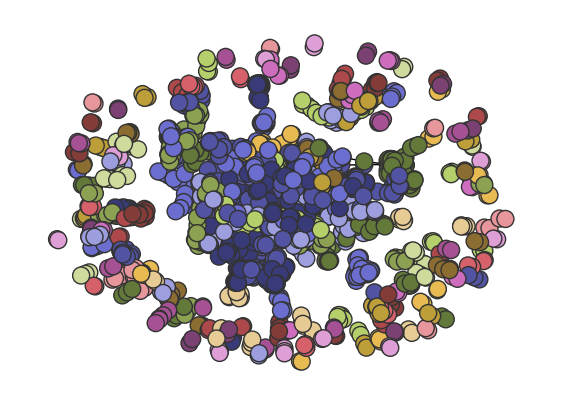

In [ ]:
import networkx as nx
import numpy as np
from collections import defaultdict
from random import shuffle
import matplotlib.pyplot as plt
import community

pos = nx.fruchterman_reingold_layout(phd_collabs)
partition = community.best_partition(phd_collabs)

# Output the best modularity score
print("Best Modularity: ", community.modularity(partition, phd_collabs))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected: ",len(np.unique(list(partition.values()))))

# Storing and showing partition as dictionary
phd_collabs_parts = dict(partition)
print("Partition Dictionary: ", phd_collabs_parts)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition.values())))))
colors_nodes = [colors_sns[partition[node]] for node in phd_collabs.nodes()]

fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

nx.draw(phd_collabs, pos=pos, node_size=150, edgecolors='.2', node_color=colors_nodes, ax=ax)

plt.show()

Best Modularity:  0.7232526057391191
Number of Communities Detected:  618
Partition Dictionary:  {0: 0, 1: 38, 2: 17, 3: 3, 4: 30, 5: 26, 6: 17, 7: 7, 8: 75, 9: 17, 10: 9, 11: 44, 12: 3, 13: 11, 14: 14, 15: 21, 16: 9, 17: 14, 18: 38, 19: 49, 20: 25, 21: 27, 22: 7, 23: 18, 24: 19, 25: 25, 26: 30, 27: 3, 28: 90, 29: 21, 30: 21, 31: 22, 32: 0, 33: 39, 34: 75, 35: 90, 36: 41, 37: 25, 38: 33, 39: 7, 40: 90, 41: 3, 42: 27, 43: 38, 44: 41, 45: 18, 46: 9, 47: 3, 48: 29, 49: 30, 50: 18, 51: 22, 52: 18, 53: 17, 54: 18, 55: 7, 56: 22, 57: 49, 58: 33, 59: 19, 60: 49, 61: 29, 62: 38, 63: 26, 64: 27, 65: 14, 66: 22, 67: 19, 68: 22, 69: 38, 70: 21, 71: 18, 72: 17, 73: 27, 74: 3, 75: 18, 76: 38, 77: 90, 78: 14, 79: 37, 80: 75, 81: 9, 82: 30, 83: 38, 84: 44, 85: 37, 86: 3, 87: 0, 88: 33, 89: 39, 90: 26, 91: 7, 92: 26, 93: 7, 94: 22, 95: 38, 96: 27, 97: 3, 98: 22, 99: 41, 100: 33, 101: 33, 102: 41, 103: 33, 104: 14, 105: 22, 106: 44, 107: 49, 108: 27, 109: 3, 110: 27, 111: 41, 112: 42, 113: 14, 114: 9, 

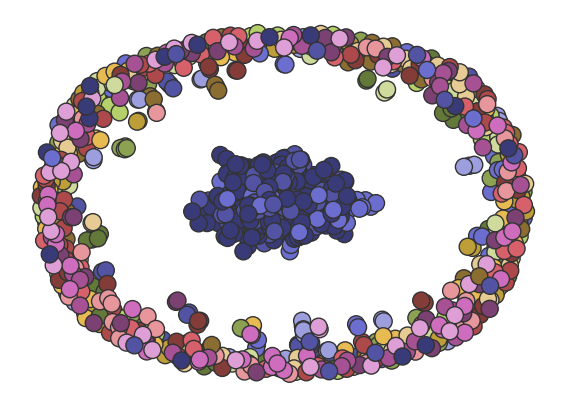

In [41]:
#(b)
degree_dict = dict(phd_collabs.degree())
degree_sequence = list(degree_dict.values())
null_phd_collabs=chung_lu_model_from_degree_sequence(degree_sequence)
pos = nx.fruchterman_reingold_layout(null_phd_collabs)
partition = community.best_partition(null_phd_collabs)
# Output the best modularity score
print("Best Modularity: ",community.modularity(partition, null_phd_collabs))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected: ",len(np.unique(list(partition.values()))))

# Storing and showing partition as dictionary
null_phd_collabs_parts = dict(partition)
print("Partition Dictionary: ", null_phd_collabs_parts)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition.values())))))
colors_nodes = [colors_sns[partition[node]] for node in null_phd_collabs.nodes()]

fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

nx.draw(null_phd_collabs, pos=pos, node_size=150, edgecolors='.2', node_color=colors_nodes, ax=ax)

plt.show()

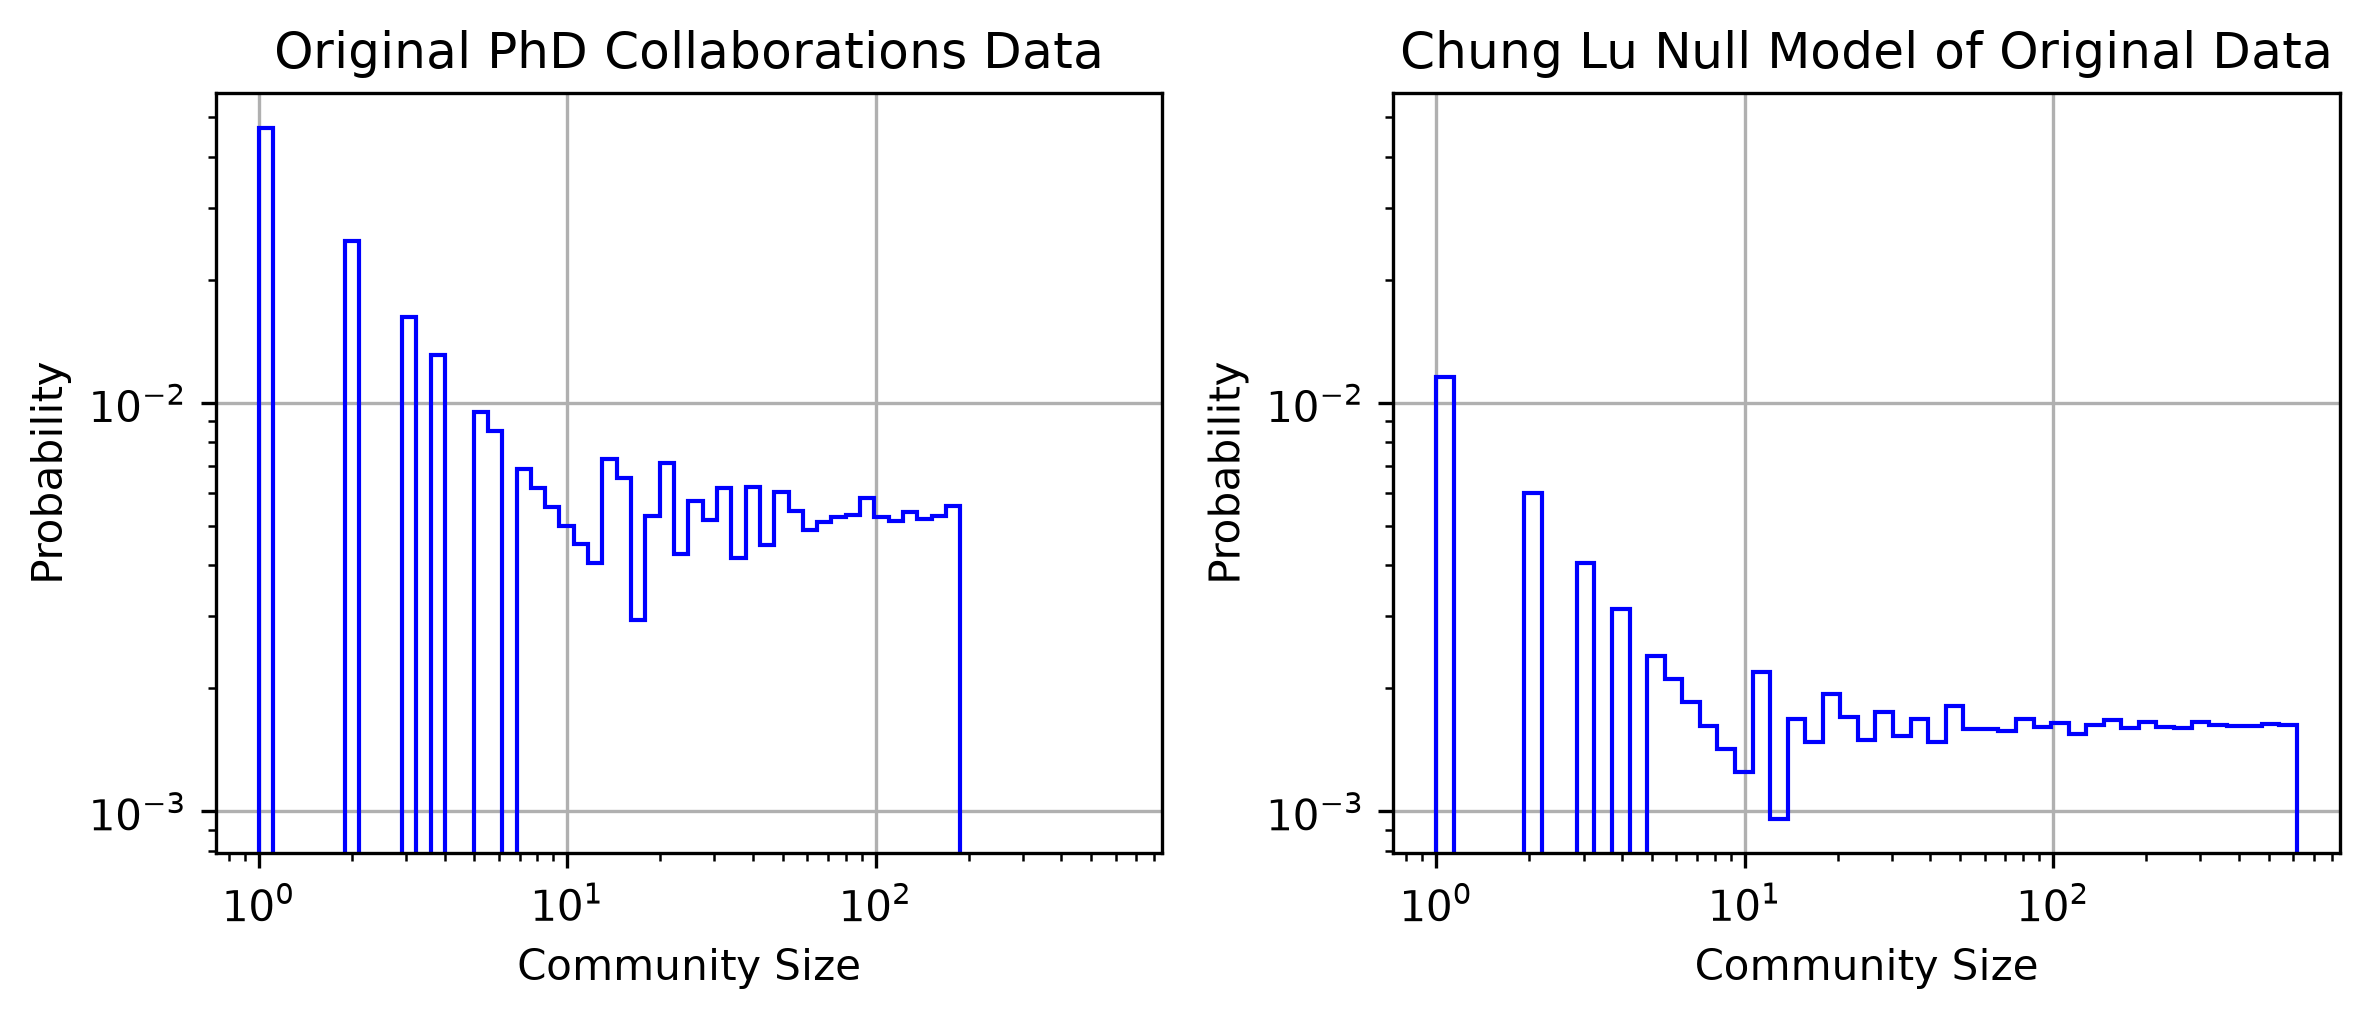

In [51]:
from collections import Counter

phd_collabs_community_sizes = Counter(phd_collabs_parts.values())
null_phd_collabs_community_sizes = Counter(null_phd_collabs_parts.values())

fig, ax = plt.subplots(1,2,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)

# Plotting the community size distribution of the original dataset
org_bins = np.geomspace(1,np.max(list(phd_collabs_community_sizes)))#Defining the smallest community as an isolated node of 1
ax[0].hist(list(phd_collabs_community_sizes),bins=org_bins, density=True,color = 'b',histtype='step')
ax[0].loglog()
ax[0].set_title("Original PhD Collaborations Data")
ax[0].set_xlabel("Community Size")
ax[0].set_ylabel("Probability")
ax[0].grid(True)
# Plotting the community size distribution of the Chung Lu Null Model of the dataset
null_bins = np.geomspace(1,np.max(list(null_phd_collabs_community_sizes)))
ax[1].hist(list(null_phd_collabs_community_sizes),bins=null_bins,density=True,color = 'b',histtype='step')
ax[1].loglog()
ax[1].set_title("Chung Lu Null Model of Original Data")
ax[1].set_xlabel("Community Size")
ax[1].set_ylabel("Probability")
ax[1].tick_params(labelleft=True)
ax[1].grid(True)

plt.tight_layout()

Analysis:

In the literature there are a vast number of different approaches to comparing two partitions: (Fortunato, Santo. “Community Detection in Graphs.” Physics Reports 486, no. 3 (2010): 75–174. https://doi.org/10.1016/j.physrep.2009.11.002.)
 provides a really nice overview of many!  
 
 I would likely approach the problem through the classification error H(X,Y) measure (M. Meilă, D. Heckerman, An experimental comparison of model-based clustering methods, Mach. Learn. 42 (1) (2001) 9–29.), which returns back the maximum overlap between the two partitions, in terms of community assignments of each node. This method seemed the most intuitive to me. Since, my intial analysis simply assigns a single community partition per node, this would allow me to compare directly to see how many nodes were assigned to the same community across the two partitions. This is good because my dataset reflects PhD Collaborations, and so being able to distinguish between a person who may be part of 1 community as opposed to definitely apart of 1 community is incredibly valuable in better understanding my dataset. 
 
 The only caveat I think would be that in real-life people tend to have multiple different communities, each of which they could be involved with at varying levels, and so by only evaluating the match across a single community assignment I miss some of that information, however to analyze assignments to multiple communities requires leveraging a different community assignment algorithm to the Louvain algorithm I utilized in my analyses above.

 Overall, I think an ideal function, f, to approach this problem would likely extend the idea of classification error but to a list of all communities a given node was assigned to across the 2 different partitions, each with an associated probability score. This would provide a more robust measure of community assignments per node that would allow one to see the following properties: whether a node is generally a part of some subset of communities, or not, to what degree if so, and how confident each partition was in assigning said communities. I think these are the primary properties the function f should have in order to determine well-enough whether a given pair of partitions are similar or not.

**Problem 3 (20 points)**

In this question we will revisit degree sequences with a focus on preferential attachment.
We have worked with G(n,p) random graphs extensively. We have also discussed how most graphs
are not random, but follow some kind of preference for homophily or highly “desirable” nodes. One
common preference is to connect to high degree nodes, reinforcing a rich-get-richer dynamic. We will
create a network growth model, where we add new vertices to a graph, and create edges to existing
vertices with a probability based on vertex i’s degree ki:
p(i) = kαi + 1∑︁n
j=0(kαj + 1)
The α parameter allows us to configure the model between a sublinear preference for high-degree
nodes (0 < α < 1), a linear preference (α = 1), and a superlinear preference (α > 1). The +1 in the
above equation ensures some chance of connecting to any vertex, even if it initially has a degree of zero.

(i) Implement the generator (4 points).

Write a graph generating function preferentialGenerator(n, a) that returns a graph with n
vertices and α = a.

(ii) Degree analysis (4 points).

Generate graphs with 1,000 nodes and alpha values of 0.1, 1, and 2. Make a plot comparing
the three degree distributions. You may use histograms, kernel-density estimates, or cumulative
distribution functions. However, your plots should be easy to interpret: select number of bins or
bin widths, log scale, or other attributes as needed to produce a high-quality figure.
We will now pivot to the random walk model of network generation. In this model, every time we
add a vertex i we add two edges. First, an edge to an existing random vertex j. Then, with probability
p, we add an edge from i to a random neighbor of j. Otherwise we instead add an edge to another
random vertex in the graph.

(iii) Implement the generator (4 points).

Write a graph generating function randomWalkGenerator(n, p) that returns a graph with n
vertices generated by random walks with probability p.

(iv) Clustering analysis (4 points).

Generate graphs with 1,000 nodes and p values of 0, 0.1, 0.5, and 0.9. Make a plot comparing the
four clustering distributions. As in part (ii), make these plots easily interpretable.
And finally...

(v) Interpretation (4 points).

Compare the graphs created by the two network growth models. What kind of structures do they
produce? In what circumstances might we want to use preferentialGenerator as a null model, and
when might the random walk model be a more appropriate null assumption?

In [ ]:
def network_growth_model(N,alpha):
    """
    Generates a Network Growth Model using preferential attachment.

    Parameters
    ----------
    N : int
        The number of vertices of the graph to generate.
    
    alpha : float
        The average number of edges to make for each node added to the graph

    Returns
    -------
    G : networkx.Graph
        A graph generated from the given number of nodes and connections per node added (alpha). 
        

    Notes
    -----
    - 
    Time Complexity
    ---------------
    The time complexity is dominated by O(N**2), where N is the number of nodes we want to add to the graph,
    each with an 'alpha' number of connections. Where alpha is bounded by N the number of new nodes we 
    want to provide alpha connections for.

    Example
    -------
    >>> N = 100
    >>> alpha = 3
    >>> G = network_growth_model(N,alpha)
    """
    #Instantiate G 
    G = nx.Graph()
    #Instantiate at least 1 node
    G.add_nodes_from(range(1))

    #Concept:
    #For every new node we want to add,
        #First if there are no connections then just add connect to what we initialized with
    #Find the probabilities of connecting to all the existing nodes currently
    #Pick 'alpha' nodes at random based on said probabilities
    #Add a new node and connect it to each of the list of 'alpha' nodes
    #Repeat for all 'N' new nodes

    while N>0:#While we still have nodes to add...
        nodes = list(G.nodes())#Get the current list of nodes...
        degs = np.array([(G.degree[n]) for n in nodes], dtype=float)#And, get their probabilities.
        
        #Translating alpha into an N value so that on average 'alpha' connections are made even if this is a float
        m = int(np.floor(alpha)) + (np.random.rand() < alpha - np.floor(alpha))
        
        #Edge Case: If this is the first run where we start with a Graph with no connections
        if degs.sum() == 0:
            chosen = nodes #then just instantiate to the few nodes we initialized with                     
        else:
            #Otherwise, pick 'm' connections to make **without replacement**,
            #  by the probability calculated from their degree(s)
            chosen = np.random.choice(nodes, size=m, replace=False, p=degs / degs.sum())
        #Add the new node as the next id number
        new_id = len(nodes)
        #And connect it to 'alpha' chosen nodes
        for node_i in chosen:
            G.add_edge(int(node_i), new_id)
        #Update N to reflect that we processed 1 new node!
        N-=1

    return G

[(0, 1), (1, 2), (2, 1)]


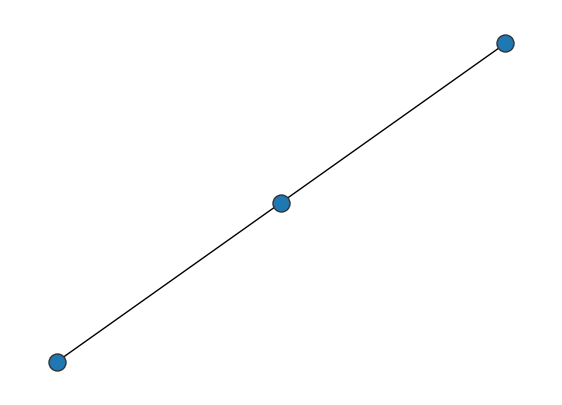

In [14]:

#Testing
import matplotlib.animation as animation
N = 10
alpha = .1
G = network_growth_model(N,alpha)

print(G.degree())
fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

visual = nx.draw(G, pos=nx.spring_layout(G), node_size=150, edgecolors='.2', ax=ax)

In [29]:
N = 1000
alpha1 = .1
alpha2 = 1
alpha3 = 2

G1 = (network_growth_model(N,alpha1))
deg1 = list(G1.degree())
G2 = (network_growth_model(N,alpha2))
deg2 = list(G2.degree())
G3 = (network_growth_model(N,alpha3))
deg3 = list(G3.degree())

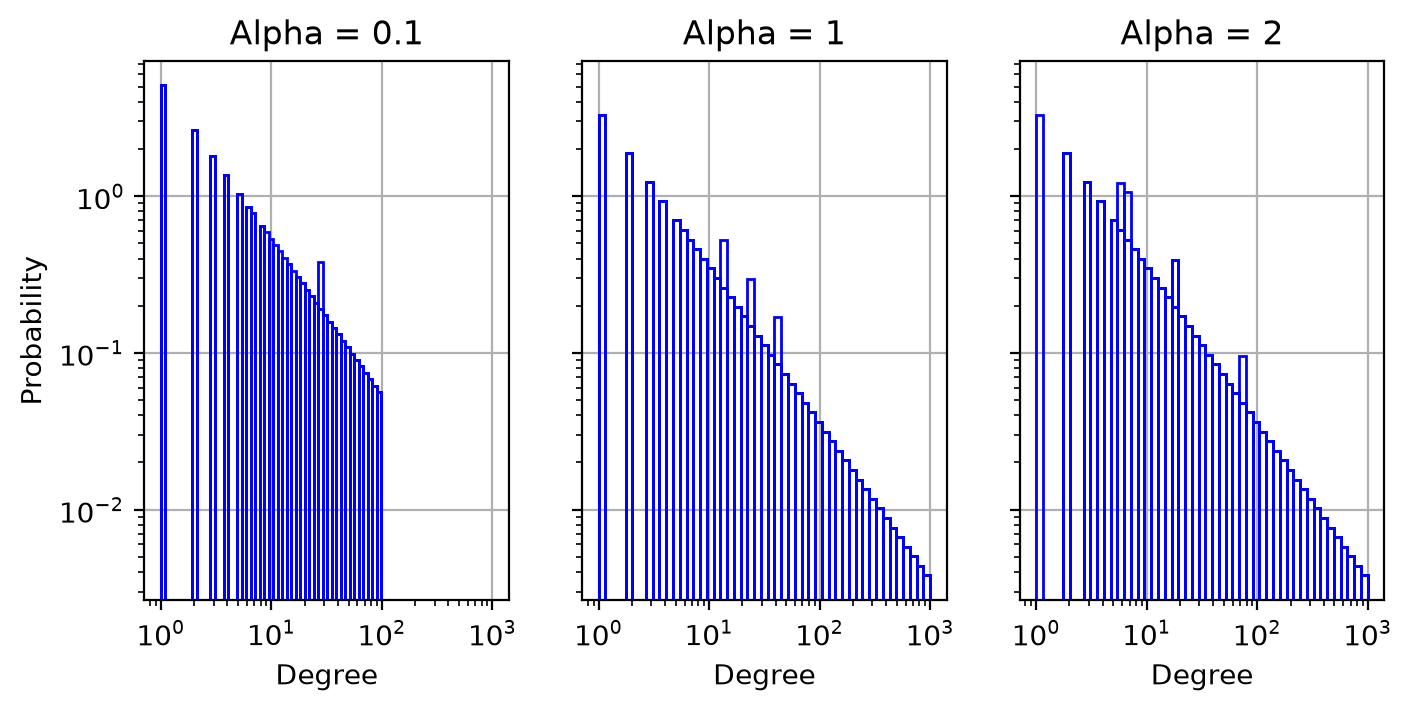

In [37]:


fig, ax = plt.subplots(1,3,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

deg_bins1 = np.geomspace(np.max([np.min(deg1),1]),np.max(deg1))
ax[0].hist(deg1,bins=deg_bins1, density=True,color = 'b',histtype='step')
ax[0].loglog()
ax[0].set_title("Alpha = 0.1")
ax[0].set_xlabel("Degree")
ax[0].set_ylabel("Probability")
ax[0].grid(True)

deg_bins2 = np.geomspace(np.max([np.min(deg2),1]),np.max(deg2))
ax[1].hist(deg2,bins=deg_bins2, density=True,color = 'b',histtype='step')
ax[1].loglog()
ax[1].set_title("Alpha = 1")
ax[1].set_xlabel("Degree")
#ax[1].set_ylabel("Probability")
ax[1].grid(True)

deg_bins3 = np.geomspace(np.max([np.min(deg3),1]),np.max(deg3))
ax[2].hist(deg3,bins=deg_bins3, density=True,color = 'b',histtype='step')
ax[2].loglog()
ax[2].set_title("Alpha = 2")
ax[2].set_xlabel("Degree")
#ax[2].set_ylabel("Probability")
ax[2].grid(True)

In [ ]:

def random_walk_generator(N,p):
    """
    Generates a Random Walk Model 

    Parameters
    ----------
    N : int
        The number of vertices of the graph to generate.
    
    p : float
        The probability we make a second edge of each new vertex, a neighbor of the vertex first connected to.

    Returns
    -------
    G : networkx.Graph
        A graph generated from the given number of nodes and connections per node added (alpha). 
        

    Notes
    -----
    - 
    Time Complexity
    ---------------
    The time complexity is dominated by O(N), where N is the number of nodes we want to add to the graph,
    each with 2 connections. 

    Example
    -------
    >>> N = 100
    >>> p = .33
    >>> G = random_walk_generator(N,p)
    
    """
    #Instantiate G 
    G = nx.Graph()
    #Instantiate at least 2 nodes (that are connected)
    G.add_edge(0,1)

    #Concept:
    # For every vertex we want to add (out of N),
    #  we add 2 edges. (i.e., m=2)
    # First edge is chosen at random (assuming no self loops?) n choose 1
    # Second edge is, if probability p, get random neighbor of j (i.e., n choose k_j) 
    # else,
    # just repeat first edge
    #

    while N>0:#While we still have nodes to add...
        nodes = list(G.nodes())#Get the current list of nodes...
        new_node= len(nodes)
        vertex_j = np.random.choice(nodes, size=1)
        nodes.remove(*vertex_j)#Prevent duplicate edges
        if np.random.rand() > p:
            G.add_edge(int(*vertex_j),new_node)
            vertex_j = np.random.choice(nodes, size=1)
            G.add_edge(int(*vertex_j),new_node)
        else:
            vertex_j_neighbor = np.random.choice(list(G.neighbors(*vertex_j)), size=1)
            G.add_edge(int(*vertex_j),new_node)
            G.add_edge(*vertex_j_neighbor,new_node)
        N-=1
    return G

[(0, 2), (1, 2), (2, 2)]


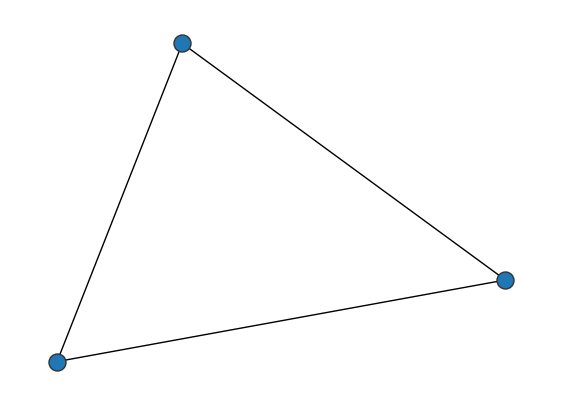

In [175]:
#Testing
import matplotlib.animation as animation
N = 1
p = 0.3
G = random_walk_generator(N,p)
 
# Expectations:
# whenever we roll a chance < p, then we will be connected to an edge and its neighbor. i.e., v_ij1 will have an edge with v_ij2, and n_i will have edges with both of them
# We will have N+2 nodes (we need a minimum of two nodes to start connecting 2 edges for every vertex)
# We will have a minimum of 2 edges per node. N=1 should be a perfect triangle

print(G.degree())
fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

visual = nx.draw(G, pos=nx.spring_layout(G), node_size=150, edgecolors='.2', ax=ax)

In [176]:
N = 1000
p1 = 0
p2 = 0.1
p3 = 0.5
p4 = 0.9

G1 = (random_walk_generator(N,p1))
cc1 = list(dict(nx.clustering(G1)).values())
G2 = (random_walk_generator(N,p2))
cc2 = list(dict(nx.clustering(G2)).values())
G3 = (random_walk_generator(N,p3))
cc3 = list(dict(nx.clustering(G3)).values())
G4 = (random_walk_generator(N,p4))
cc4 = list(dict(nx.clustering(G4)).values())

print(cc1)

[0.021052631578947368, 0.04395604395604396, 0.08333333333333333, 0.07272727272727272, 0.13333333333333333, 0.022222222222222223, 0.02857142857142857, 0, 0, 0.08333333333333333, 0.05555555555555555, 0.025, 0, 0.027777777777777776, 0, 0.015151515151515152, 0, 0, 0.009523809523809525, 0, 0.06666666666666667, 0.01818181818181818, 0, 0.06666666666666667, 0, 0, 0, 0, 0.027777777777777776, 0, 0, 0, 0.007352941176470588, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.01818181818181818, 0, 0.03571428571428571, 0, 0.01818181818181818, 0, 0, 0.022222222222222223, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.022222222222222223, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.03571428571428571, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.06666666666666667, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.06666666666666667, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

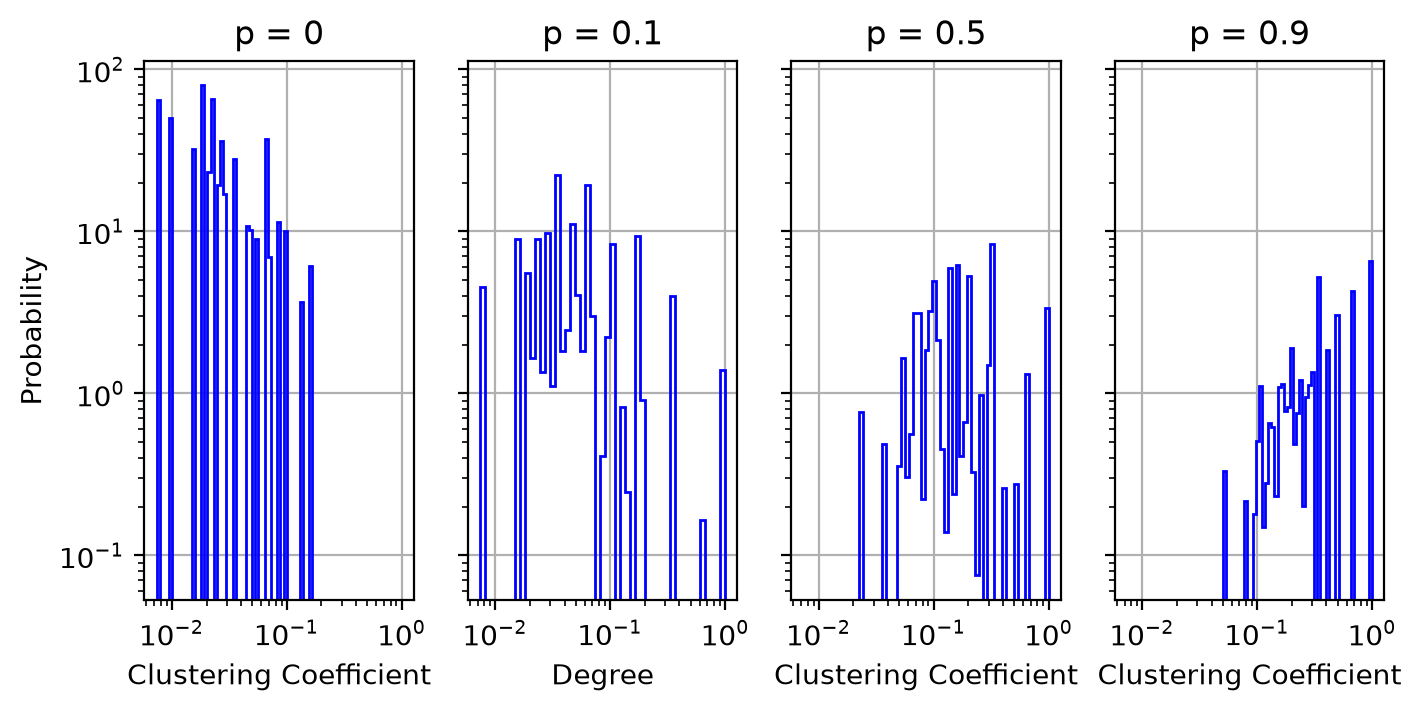

In [177]:
fig, ax = plt.subplots(1,4,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Since there are cases where the minimum CC is 0, 
# I'm starting the plot with the second-most minimum

#Gathering 2nd most mins
cc1=np.asarray(cc1)
cc1_min2= np.amin(cc1[cc1 != np.amin(cc1)])
cc2=np.asarray(cc2)
cc2_min2= np.amin(cc2[cc2 != np.amin(cc2)])
cc3=np.asarray(cc3)
cc3_min2= np.amin(cc3[cc3 != np.amin(cc3)])
cc4=np.asarray(cc4)
cc4_min2= np.amin(cc4[cc4 != np.amin(cc4)])

cc_bins1 = np.geomspace(cc1_min2,np.max(cc1))
ax[0].hist(cc1,bins=cc_bins1, density=True,color = 'b',histtype='step')
ax[0].loglog()
ax[0].set_title("p = 0")
ax[0].set_xlabel("Clustering Coefficient")
ax[0].set_ylabel("Probability")
ax[0].grid(True)

cc_bins2 = np.geomspace(cc2_min2,np.max(cc2))
ax[1].hist(cc2,bins=cc_bins2, density=True,color = 'b',histtype='step')
ax[1].loglog()
ax[1].set_title("p = 0.1")
ax[1].set_xlabel("Degree")
#ax[1].set_ylabel("Probability")
ax[1].grid(True)

cc_bins3 = np.geomspace(cc3_min2,np.max(cc3))
ax[2].hist(cc3,bins=cc_bins3, density=True,color = 'b',histtype='step')
ax[2].loglog()
ax[2].set_title("p = 0.5")
ax[2].set_xlabel("Clustering Coefficient")
#ax[2].set_ylabel("Probability")
ax[2].grid(True)

cc_bins4 = np.geomspace(cc4_min2,np.max(cc4))
ax[3].hist(cc4,bins=cc_bins4, density=True,color = 'b',histtype='step')
ax[3].loglog()
ax[3].set_title("p = 0.9")
ax[3].set_xlabel("Clustering Coefficient")
#ax[3].set_ylabel("Probability")
ax[3].grid(True)

Interpretation:
The network-growth model produced degree distributions that follow a power law curve (i.e., a linear shape on a log-log plot). This means it produced networks structures where hubs emerged and tended to be the places where new nodes made connections to. The randomWalkGenerator on the other hand allowed us to generate various levels of clustering coefficient distributions by picking different p values. A preferentialGenerator may be a better suited null model therefore when we want to simulate or model a network where we know there are strong hubs that dominate the network. Take the internet for example, it's a well-known fact that the most popular websites dominate most searches and webpage requests online, and as such many new websites may promote their own website through ads on this site (i.e., seek out a connection to it) through for example, running ads on Google to garner more attention, or, posting an opinion piece on a well known newpaper website to bring attention to your own, etc. Conversely, a randomWalkGenerator may be more helpful when you are looking at perhaps a relatively smaller but known to be tighter knit network. Say, a circle of friends, people, researchers, etc. Here one can leverage the randomWalkGenerator by tuning the p-value to the level of clustering observed in the groups of interest, to observe this level of clustering amongst a network of these tight-knit circles 

**Problem 4 (20 points)**

We are training you to conduct original research, and a crucial component of that is a literature review.
We can conduct literature reviews for several reasons, including familiarizing ourselves with a topic of
study, a set of related methods, or the conventional wisdom of a field. When beginning a research project
we typically want to know whether our research question has been asked before (and if so, using what
tools and with what data), what related questions have been asked, and what gaps in understanding
remain that we can try to answer.
Today we will start small. Search Google Scholar for five papers on different community detection
algorithms. Don’t use the ones we’ve discussed extensively in class (label propagation, Louvain, Girvan-
Newman). For each algorithm, answer the following:

(a) What measure is being optimized (how do we know a given partition is optimal or good? Are they use modularity maximization, or something else?)

(b) Algorithmically (a high level explanation in a few sentences is fine), how are partitions selected /
sampled?

(c) When did this technique come out? Does the journal or conference suggest what field this al-
gorithm is used in? Is it terribly obscure? (We can use citation count as a proxy for obscurity
here)

(d) Is the algorithm particularly well-suited to certain kinds of graphs? (Does it assume sparse graphs?
A core-periphery structure? Does it scale well / poorly? Add a little context about where you
might / should not use this algorithm)

I encourage you to read selectively; you want to understand how these algorithms work and where
and how they could be used, but you don’t need to understand every check for division by zero or the
full literature review of how this approach has been used in MRI analysis and how detected neuronal
communities differ from established medical literature. Read papers for what you need from them.

**Problem 5 OPTIONAL (5 bonus points)**

For every problem set this semester, there will be an opportunity to earn extra credit. Since this is
a new(-ish) course, we are eager to receive genuine feedback on the material, pace, instruction style,
etc. of the course so far. Please provide any feedback about the lectures in recent weeks and/or this
assignment